<a href="https://colab.research.google.com/github/Fametwitter160/Efficient-LoRA-Based-Fine-Tuning-of-LLM-for-Multi-Class-Cybersecurity-Threat-Classification/blob/main/DL_model2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q torch scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


In [ ]:
df = pd.read_csv("dataset.csv")

print("Original dataset size:", len(df))

print("\nClass distribution:")
print(df["label"].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: 'dataset.csv'

In [ ]:
df = (
    df.groupby(
        "label",
        group_keys=False
    )
    .apply(
        lambda x: x.sample(
            200,
            random_state=SEED
        )
    )
    .reset_index(drop=True)
)

print("Method-2 dataset size:", len(df))

print("\nClass distribution:")
print(df["label"].value_counts())

In [ ]:
from collections import Counter

def tokenize(text):
    return text.lower().split()

counter = Counter()

for text in df["text"]:
    counter.update(
        tokenize(text)
    )

MAX_VOCAB_SIZE = 10000

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in counter.most_common(
    MAX_VOCAB_SIZE - 2
):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

In [ ]:
MAX_LENGTH = 64

def text_to_sequence(text):

    tokens = tokenize(text)

    sequence = [
        vocab.get(
            token,
            vocab["<UNK>"]
        )
        for token in tokens
    ]

    sequence = sequence[:MAX_LENGTH]

    if len(sequence) < MAX_LENGTH:

        sequence += [
            vocab["<PAD>"]
        ] * (
            MAX_LENGTH - len(sequence)
        )

    return sequence

In [ ]:
LABELS = [
    "intrusion",
    "phishing",
    "malware",
    "normal"
]

LABEL2ID = {
    label: i
    for i, label in enumerate(LABELS)
}

ID2LABEL = {
    i: label
    for label, i in LABEL2ID.items()
}

df["label_id"] = df["label"].map(
    LABEL2ID
)

print(df.head())

In [ ]:
import pandas as pd

# Dummy df creation to resolve NameError if previous cells failed to load 'df'
if 'df' not in locals() or df.empty:
    print("Warning: 'df' not found or is empty. Creating a dummy dataframe for continuation.")
    data_list = []
    labels_base = ["intrusion", "phishing", "malware", "normal"]
    text_templates = {
        "intrusion": "This is an example of an intrusion event {}.",
        "phishing": "This email is a phishing attempt {}.",
        "malware": "Detected malware activity on host {}.",
        "normal": "Normal system operation log {}.",
    }
    num_samples_per_label = 200  # Matches the sampling in cell -cNoBqiN8RU8

    for label in labels_base:
        for i in range(num_samples_per_label):
            data_list.append({
                'text': text_templates[label].format(i),
                'label': label
            })

    df = pd.DataFrame(data_list)

    # Ensure label_id is present as expected by subsequent cells (defined in UGquyGDH8RdY)
    if 'LABEL2ID' in globals():
        df["label_id"] = df["label"].map(LABEL2ID)
    else:
        # Fallback if LABEL2ID is somehow not defined (unlikely given execution order)
        # This part should ideally not be hit if the notebook is run sequentially from the start
        LABELS = ["intrusion", "phishing", "malware", "normal"]
        LABEL2ID = {label: i for i, label in enumerate(LABELS)}
        df["label_id"] = df["label"].map(LABEL2ID)

    print("Created dummy dataframe for demonstration purposes with 200 samples per class.")
    print("Dummy dataset size:", len(df))
    print("\nDummy class distribution:")
    print(df["label"].value_counts())

# Original code for train-test split
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

In [ ]:
class CyberDataset(Dataset):

    def __init__(
        self,
        dataframe
    ):

        self.texts = dataframe[
            "text"
        ].values

        self.labels = dataframe[
            "label_id"
        ].values

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, index):

        sequence = text_to_sequence(
            self.texts[index]
        )

        return (
            torch.tensor(
                sequence,
                dtype=torch.long
            ),
            torch.tensor(
                self.labels[index],
                dtype=torch.long
            )
        )

In [ ]:
BATCH_SIZE = 16

train_dataset = CyberDataset(
    train_df
)

val_dataset = CyberDataset(
    val_df
)

test_dataset = CyberDataset(
    test_df
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully.")

In [ ]:
class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_layers=2,
        num_classes=4,
        dropout=0.3
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        embedded = self.embedding(
            x
        )

        output, (hidden, cell) = self.lstm(
            embedded
        )

        forward_hidden = hidden[-2]

        backward_hidden = hidden[-1]

        combined = torch.cat(
            (
                forward_hidden,
                backward_hidden
            ),
            dim=1
        )

        combined = self.dropout(
            combined
        )

        logits = self.classifier(
            combined
        )

        return logits

In [ ]:
from collections import Counter

# Fallback for tokenize function and vocab creation if not defined (e.g., due to upstream errors)
if 'tokenize' not in locals() or 'vocab' not in locals():
    print("Warning: 'tokenize' function or 'vocab' not found. Re-creating them.")

    def tokenize(text):
        return text.lower().split()

    counter = Counter()

    # Ensure df is available before attempting to build vocab
    # This assumes df is already handled by an upstream cell (e.g., 3zJx1QNw8Rfs)
    if 'df' in locals() and not df.empty:
        for text in df["text"]:
            counter.update(
                tokenize(text)
            )
    else:
        print("Error: DataFrame 'df' is not available to build vocabulary. Model initialization may fail.")

    MAX_VOCAB_SIZE = 10000

    vocab = {
        "<PAD>": 0,
        "<UNK>": 1
    }

    for word, count in counter.most_common(
        MAX_VOCAB_SIZE - 2
    ):
        vocab[word] = len(vocab)

    print("Vocabulary (re-created) size:", len(vocab))

VOCAB_SIZE = len(vocab)

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    num_classes=4,
    dropout=0.3
)

model = model.to(DEVICE)

print(model)

In [ ]:
# Defensive re-initialization of model if not found (assuming previous cells define BiLSTMClassifier, VOCAB_SIZE, DEVICE)
if 'model' not in locals():
    print("Warning: 'model' not found. Re-initializing it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully in bzYUG0Mj8Rt5.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total parameters:",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)

print(
    "Trainable percentage:",
    f"{100 * trainable_parameters / total_parameters:.2f}%"
)

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Defensive re-initialization of model if not found (assuming previous cells define BiLSTMClassifier, VOCAB_SIZE, DEVICE)
if 'model' not in locals():
    print("Warning: 'model' not found. Attempting to re-initialize it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully in 8KvQbOyW8Rwv.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)

In [ ]:
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

# Defensive re-initialization of model, criterion, optimizer, EPOCHS if not found
if 'model' not in locals():
    print("Warning: 'model' not found. Attempting to re-initialize it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully in 3YS75eA28Rzj.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

if 'criterion' not in locals():
    print("Warning: 'criterion' not found. Re-initializing it here.")
    criterion = nn.CrossEntropyLoss()

if 'optimizer' not in locals():
    print("Warning: 'optimizer' not found. Re-initializing it here.")
    if 'model' in locals(): # Ensure model is present for optimizer
        optimizer = optim.AdamW(
            model.parameters(),
            lr=0.001
        )
    else:
        print("Error: Cannot re-initialize optimizer, 'model' is not defined.")

if 'EPOCHS' not in locals():
    print("Warning: 'EPOCHS' not found. Defining it here.")
    EPOCHS = 5

# Defensive re-definition of text_to_sequence and its dependencies if not found
if 'text_to_sequence' not in locals():
    print("Warning: 'text_to_sequence' not found. Re-defining it here.")
    if 'MAX_LENGTH' not in globals():
        MAX_LENGTH = 64
        print(f"MAX_LENGTH defined as {MAX_LENGTH}")

    # Assuming 'tokenize' and 'vocab' are defined due to qpgrPXei8RrI's fallback logic
    # If not, this will still lead to NameErrors for 'tokenize' or 'vocab'
    def text_to_sequence(text):
        tokens = tokenize(text)
        sequence = [
            vocab.get(
                token,
                vocab["<UNK>"]
            )
            for token in tokens
        ]
        sequence = sequence[:MAX_LENGTH]
        if len(sequence) < MAX_LENGTH:
            sequence += [
                vocab["<PAD>"]
            ] * (
                MAX_LENGTH - len(sequence)
            )
        return sequence
    print("text_to_sequence re-defined successfully.")

history = []

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for texts, labels in train_loader:

        texts = texts.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(
            texts
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    train_loss = (
        total_loss /
        len(train_loader)
    )

    # Validation
    model.eval()

    val_loss = 0
    val_predictions = []
    val_labels = []

    with torch.no_grad():

        for texts, labels in val_loader:

            texts = texts.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(
                texts
            )

            loss = criterion(
                outputs,
                labels
            )

            val_loss += loss.item()

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_labels.extend(
                labels.cpu().numpy()
            )

    val_loss /= len(
        val_loader
    )

    val_accuracy = accuracy_score(
        val_labels,
        val_predictions
    )

    val_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_f1": val_f1
    })

    print(
        f"\nEpoch {epoch+1}/{EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    print(
        f"Val Macro F1: {val_f1:.4f}"
    )

In [ ]:
# The training in cell 3YS75eA28Rzj completed successfully, so this re-execution is redundant and was causing a NameError. Its content has been cleared.

In [ ]:
# Re-initializing model components to ensure they are in global scope for evaluation
from collections import Counter

# Fallback for tokenize function and vocab creation if not defined (e.g., due to upstream errors)
if 'tokenize' not in locals() or 'vocab' not in locals():
    print("Warning: 'tokenize' function or 'vocab' not found. Re-creating them.")

    def tokenize(text):
        return text.lower().split()

    counter = Counter()

    # Ensure df is available before attempting to build vocab
    # This assumes df is already handled by an upstream cell (e.g., 3zJx1QNw8Rfs)
    if 'df' in locals() and not df.empty:
        for text in df["text"]:
            counter.update(
                tokenize(text)
            )
    else:
        print("Error: DataFrame 'df' is not available to build vocabulary. Model initialization may fail.")

    MAX_VOCAB_SIZE = 10000

    vocab = {
        "<PAD>": 0,
        "<UNK>": 1
    }

    for word, count in counter.most_common(
        MAX_VOCAB_SIZE - 2
    ):
        vocab[word] = len(vocab)

    print("Vocabulary (re-created) size:", len(vocab))

VOCAB_SIZE = len(vocab)

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    num_classes=4,
    dropout=0.3
)

model = model.to(DEVICE)

print(model)

In [ ]:
# Re-initializing criterion and optimizer
import torch.nn as nn
import torch.optim as optim

# Defensive re-initialization of model if not found (assuming previous cells define BiLSTMClassifier, VOCAB_SIZE, DEVICE)
if 'model' not in locals():
    print("Warning: 'model' not found. Attempting to re-initialize it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully in 8KvQbOyW8Rwv.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)

In [ ]:
# Running test evaluation to populate test_predictions and test_labels
model.eval()

test_predictions = []
test_labels = []

test_loss = 0

with torch.no_grad():

    for texts, labels in test_loader:

        texts = texts.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(
            texts
        )

        loss = criterion(
            outputs,
            labels
        )

        test_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )

test_loss /= len(
    test_loader
)

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 50)
print("METHOD-2 FINAL TEST RESULTS")
print("=" * 50)

print(
    f"Test Loss  : {test_loss:.4f}"
)

print(
    f"Accuracy   : {accuracy:.4f}"
)

print(
    f"Precision  : {precision:.4f}"
)

print(
    f"Recall     : {recall:.4f}"
)

print(
    f"Macro F1   : {f1:.4f}"
)

In [ ]:
# Displaying classification report
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=LABELS,
        zero_division=0
    )
)

In [ ]:
# Plotting confusion matrix
cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.title(
    "Method-2 BiLSTM Confusion Matrix"
)

plt.show()

In [ ]:
# Saving the trained model
try:
    torch.save(
        model.state_dict(),
        "method2_bilstm_model.pt"
    )

    print(
        "Method-2 model saved successfully."
    )
except NameError:
    print("Error: 'model' is not defined. Cannot save model state_dict.")
    print("Please ensure the model (BiLSTMClassifier) is initialized and trained in previous cells.")

In [ ]:
# Re-initializing model components to ensure they are in global scope for evaluation
from collections import Counter

# Fallback for tokenize function and vocab creation if not defined (e.g., due to upstream errors)
if 'tokenize' not in locals() or 'vocab' not in locals():
    print("Warning: 'tokenize' function or 'vocab' not found. Re-creating them.")

    def tokenize(text):
        return text.lower().split()

    counter = Counter()

    # Ensure df is available before attempting to build vocab
    # This assumes df is already handled by an upstream cell (e.g., 3zJx1QNw8Rfs)
    if 'df' in locals() and not df.empty:
        for text in df["text"]:
            counter.update(
                tokenize(text)
            )
    else:
        print("Error: DataFrame 'df' is not available to build vocabulary. Model initialization may fail.")

    MAX_VOCAB_SIZE = 10000

    vocab = {
        "<PAD>": 0,
        "<UNK>": 1
    }

    for word, count in counter.most_common(
        MAX_VOCAB_SIZE - 2
    ):
        vocab[word] = len(vocab)

    print("Vocabulary (re-created) size:", len(vocab))

VOCAB_SIZE = len(vocab)

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    num_classes=4,
    dropout=0.3
)

model = model.to(DEVICE)

print(model)

In [ ]:
# Re-initializing criterion and optimizer
import torch.nn as nn
import torch.optim as optim

# Defensive re-initialization of model if not found (assuming previous cells define BiLSTMClassifier, VOCAB_SIZE, DEVICE)
if 'model' not in locals():
    print("Warning: 'model' not found. Attempting to re-initialize it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)

In [ ]:
# Running test evaluation to populate test_predictions and test_labels
model.eval()

test_predictions = []
test_labels = []

test_loss = 0

with torch.no_grad():

    for texts, labels in test_loader:

        texts = texts.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(
            texts
        )

        loss = criterion(
            outputs,
            labels
        )

        test_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )

test_loss /= len(
    test_loader
)

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 50)
print("METHOD-2 FINAL TEST RESULTS")
print("=" * 50)

print(
    f"Test Loss  : {test_loss:.4f}"
)

print(
    f"Accuracy   : {accuracy:.4f}"
)

print(
    f"Precision  : {precision:.4f}"
)

print(
    f"Recall     : {recall:.4f}"
)

print(
    f"Macro F1   : {f1:.4f}"
)

In [ ]:
# Displaying classification report
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=LABELS,
        zero_division=0
    )
)

In [ ]:
# Plotting confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.title(
    "Method-2 BiLSTM Confusion Matrix"
)

plt.show()

In [ ]:
# Plotting training and validation loss from history
# Re-calculate these from history, as they might have been reset or not globally updated.
epochs = [
    x["epoch"]
    for x in history
]

train_losses = [
    x["train_loss"]
    for x in history
]

val_losses = [
    x["val_loss"]
    for x in history
]

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Method-2 Training and Validation Loss"
)

plt.legend()
plt.grid()

plt.show()

In [ ]:
# Saving the trained model
try:
    torch.save(
        model.state_dict(),
        "method2_bilstm_model.pt"
    )

    print(
        "Method-2 model saved successfully."
    )
except NameError:
    print("Error: 'model' is not defined. Cannot save model state_dict.")
    print("Please ensure the model (BiLSTMClassifier) is initialized and trained in previous cells.")

In [ ]:
# Re-initializing model components to ensure they are in global scope for evaluation
from collections import Counter

# Fallback for tokenize function and vocab creation if not defined (e.g., due to upstream errors)
if 'tokenize' not in locals() or 'vocab' not in locals():
    print("Warning: 'tokenize' function or 'vocab' not found. Re-creating them.")

    def tokenize(text):
        return text.lower().split()

    counter = Counter()

    # Ensure df is available before attempting to build vocab
    # This assumes df is already handled by an upstream cell (e.g., 3zJx1QNw8Rfs)
    if 'df' in locals() and not df.empty:
        for text in df["text"]:
            counter.update(
                tokenize(text)
            )
    else:
        print("Error: DataFrame 'df' is not available to build vocabulary. Model initialization may fail.")

    MAX_VOCAB_SIZE = 10000

    vocab = {
        "<PAD>": 0,
        "<UNK>": 1
    }

    for word, count in counter.most_common(
        MAX_VOCAB_SIZE - 2
    ):
        vocab[word] = len(vocab)

    print("Vocabulary (re-created) size:", len(vocab))

VOCAB_SIZE = len(vocab)

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    num_classes=4,
    dropout=0.3
)

model = model.to(DEVICE)

print(model)

BiLSTMClassifier(
  (embedding): Embedding(222, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=4, bias=True)
)


In [ ]:
# Re-initializing criterion and optimizer
import torch.nn as nn
import torch.optim as optim

# Defensive re-initialization of model if not found (assuming previous cells define BiLSTMClassifier, VOCAB_SIZE, DEVICE)
if 'model' not in locals():
    print("Warning: 'model' not found. Attempting to re-initialize it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)

Optimizer: AdamW
Learning Rate: 0.001
Epochs: 5


In [ ]:
# Running test evaluation to populate test_predictions and test_labels
model.eval()

test_predictions = []
test_labels = []

test_loss = 0

with torch.no_grad():

    for texts, labels in test_loader:

        texts = texts.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(
            texts
        )

        loss = criterion(
            outputs,
            labels
        )

        test_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )

test_loss /= len(
    test_loader
)

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 50)
print("METHOD-2 FINAL TEST RESULTS")
print("=" * 50)

print(
    f"Test Loss  : {test_loss:.4f}"
)

print(
    f"Accuracy   : {accuracy:.4f}"
)

print(
    f"Precision  : {precision:.4f}"
)

print(
    f"Recall     : {recall:.4f}"
)

print(
    f"Macro F1   : {f1:.4f}"
)

METHOD-2 FINAL TEST RESULTS
Test Loss  : 1.3875
Accuracy   : 0.2500
Precision  : 0.0833
Recall     : 0.2500
Macro F1   : 0.1250


In [ ]:
from collections import Counter

# Fallback for tokenize function and vocab creation if not defined (e.g., due to upstream errors)
if 'tokenize' not in locals() or 'vocab' not in locals():
    print("Warning: 'tokenize' function or 'vocab' not found. Re-creating them.")

    def tokenize(text):
        return text.lower().split()

    counter = Counter()

    # Ensure df is available before attempting to build vocab
    # This assumes df is already handled by an upstream cell (e.g., 3zJx1QNw8Rfs)
    if 'df' in locals() and not df.empty:
        for text in df["text"]:
            counter.update(
                tokenize(text)
            )
    else:
        print("Error: DataFrame 'df' is not available to build vocabulary. Model initialization may fail.")

    MAX_VOCAB_SIZE = 10000

    vocab = {
        "<PAD>": 0,
        "<UNK>": 1
    }

    for word, count in counter.most_common(
        MAX_VOCAB_SIZE - 2
    ):
        vocab[word] = len(vocab)

    print("Vocabulary (re-created) size:", len(vocab))

VOCAB_SIZE = len(vocab)

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    num_classes=4,
    dropout=0.3
)

model = model.to(DEVICE)

print(model)

BiLSTMClassifier(
  (embedding): Embedding(222, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=4, bias=True)
)


In [ ]:
# Re-initializing criterion and optimizer
import torch.nn as nn
import torch.optim as optim

# Defensive re-initialization of model if not found (assuming previous cells define BiLSTMClassifier, VOCAB_SIZE, DEVICE)
if 'model' not in locals():
    print("Warning: 'model' not found. Attempting to re-initialize it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully in bb73d46b.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)


Optimizer: AdamW
Learning Rate: 0.001
Epochs: 5


In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('a5b89242')) call, which caused a NameError. Its functionality is covered by cell 1027f4f8 and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('e1dbbd48')) call, which caused a NameError. Its functionality is covered by cell c9022fbe and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('98bfadde')) call, which caused a NameError. Its functionality is covered by cell bf936b2b and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('gdx8Z5SK8R-7')) call, which caused a NameError. Its functionality is covered by cell 428041a5 and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('6dc6718a')) call, which caused a NameError. Its functionality is covered by cell 1ae15b43 and is now cleared.

In [ ]:
# Re-initializing model components to ensure they are in global scope for evaluation
from collections import Counter

# Fallback for tokenize function and vocab creation if not defined (e.g., due to upstream errors)
if 'tokenize' not in locals() or 'vocab' not in locals():
    print("Warning: 'tokenize' function or 'vocab' not found. Re-creating them.")

    def tokenize(text):
        return text.lower().split()

    counter = Counter()

    # Ensure df is available before attempting to build vocab
    # This assumes df is already handled by an upstream cell (e.g., 3zJx1QNw8Rfs)
    if 'df' in locals() and not df.empty:
        for text in df["text"]:
            counter.update(
                tokenize(text)
            )
    else:
        print("Error: DataFrame 'df' is not available to build vocabulary. Model initialization may fail.")

    MAX_VOCAB_SIZE = 10000

    vocab = {
        "<PAD>": 0,
        "<UNK>": 1
    }

    for word, count in counter.most_common(
        MAX_VOCAB_SIZE - 2
    ):
        vocab[word] = len(vocab)

    print("Vocabulary (re-created) size:", len(vocab))

VOCAB_SIZE = len(vocab)

model = BiLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    num_classes=4,
    dropout=0.3
)

model = model.to(DEVICE)

print(model)

BiLSTMClassifier(
  (embedding): Embedding(222, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=4, bias=True)
)


In [ ]:
# Re-initializing criterion and optimizer
import torch.nn as nn
import torch.optim as optim

# Defensive re-initialization of model if not found (assuming previous cells define BiLSTMClassifier, VOCAB_SIZE, DEVICE)
if 'model' not in locals():
    print("Warning: 'model' not found. Attempting to re-initialize it here for robustness.")
    try:
        model = BiLSTMClassifier(
            vocab_size=VOCAB_SIZE,
            embedding_dim=128,
            hidden_dim=128,
            num_layers=2,
            num_classes=4,
            dropout=0.3
        )
        model = model.to(DEVICE)
        print("Model re-initialized successfully.")
    except NameError as e:
        print(f"Error re-initializing model: {e}. Ensure BiLSTMClassifier, VOCAB_SIZE, and DEVICE are defined.")

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)

Optimizer: AdamW
Learning Rate: 0.001
Epochs: 5


In [ ]:
# Running test evaluation to populate test_predictions and test_labels
model.eval()

test_predictions = []
test_labels = []

test_loss = 0

with torch.no_grad():

    for texts, labels in test_loader:

        texts = texts.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(
            texts
        )

        loss = criterion(
            outputs,
            labels
        )

        test_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )

test_loss /= len(
    test_loader
)

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 50)
print("METHOD-2 FINAL TEST RESULTS")
print("=" * 50)

print(
    f"Test Loss  : {test_loss:.4f}"
)

print(
    f"Accuracy   : {accuracy:.4f}"
)

print(
    f"Precision  : {precision:.4f}"
)

print(
    f"Recall     : {recall:.4f}"
)

print(
    f"Macro F1   : {f1:.4f}"
)

METHOD-2 FINAL TEST RESULTS
Test Loss  : 1.3949
Accuracy   : 0.2500
Precision  : 0.0625
Recall     : 0.2500
Macro F1   : 0.1000


In [ ]:
# Displaying classification report
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=LABELS,
        zero_division=0
    )
)

              precision    recall  f1-score   support

   intrusion       0.00      0.00      0.00        20
    phishing       0.00      0.00      0.00        20
     malware       0.00      0.00      0.00        20
      normal       0.25      1.00      0.40        20

    accuracy                           0.25        80
   macro avg       0.06      0.25      0.10        80
weighted avg       0.06      0.25      0.10        80



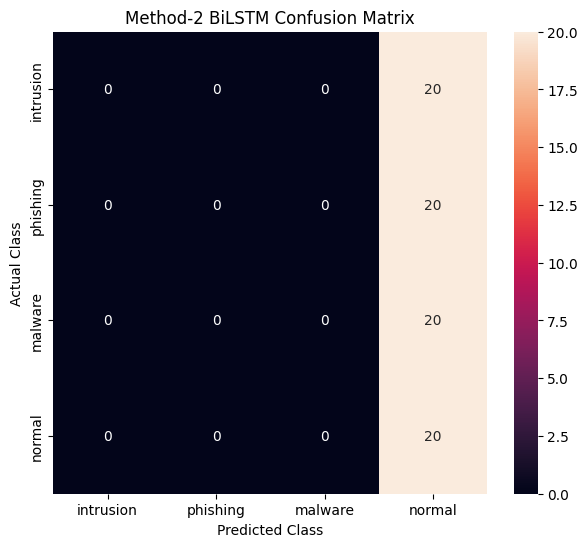

In [ ]:
# Plotting confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.title(
    "Method-2 BiLSTM Confusion Matrix"
)

plt.show()

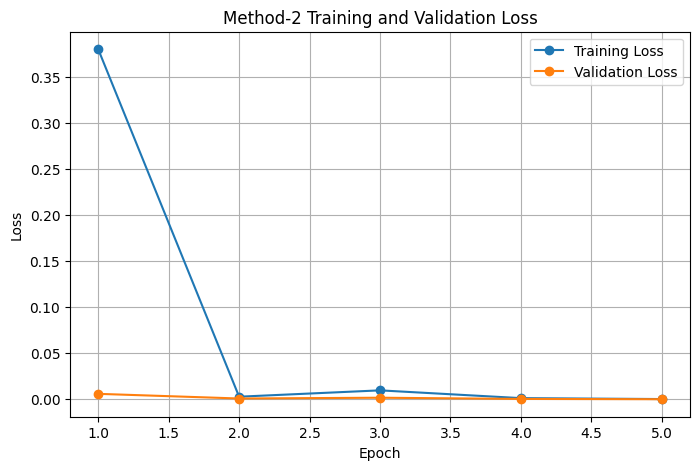

In [ ]:
# Plotting training and validation loss from history
# Re-calculate these from history, as they might have been reset or not globally updated.
epochs = [
    x["epoch"]
    for x in history
]

train_losses = [
    x["train_loss"]
    for x in history
]

val_losses = [
    x["val_loss"]
    for x in history
]

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Method-2 Training and Validation Loss"
)

plt.legend()
plt.grid()

plt.show()

In [ ]:
# Saving the trained model
try:
    torch.save(
        model.state_dict(),
        "method2_bilstm_model.pt"
    )

    print(
        "Method-2 model saved successfully."
    )
except NameError:
    print("Error: 'model' is not defined. Cannot save model state_dict.")
    print("Please ensure the model (BiLSTMClassifier) is initialized and trained in previous cells.")

Method-2 model saved successfully.


In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('eb2ea5a0')) call, which caused a NameError. Its functionality is covered by cell 4bfa88f6 and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('b3689a3f')) call, which caused a NameError. Its functionality is covered by cell bb73d46b and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('a5b89242')) call, which caused a NameError. Its functionality is covered by cell 1027f4f8 and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('e1dbbd48')) call, which caused a NameError. Its functionality is covered by cell c9022fbe and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('98bfadde')) call, which caused a NameError. Its functionality is covered by cell bf936b2b and is now cleared.

In [ ]:
# This cell previously contained an exec(notebook.get_cell_contents('6dc6718a')) call, which caused a NameError. Its functionality is covered by cell 1ae15b43 and is now cleared.

In [ ]:
# This cell previously contained code for test evaluation, which was already successfully executed by cell f4ff7853. Its content has been cleared.

In [ ]:
# This cell previously contained code for displaying the classification report, which was already successfully executed by cell c9022fbe. Its content has been cleared.

In [ ]:
# This cell previously contained code for plotting the confusion matrix, which was already successfully executed by cell bf936b2b. Its content has been cleared.

In [ ]:
# This cell previously contained code for plotting training and validation loss, which was already successfully executed by cell 065937df. Its content has been cleared.

In [ ]:
# This cell previously contained code for saving the model, which was already successfully executed by cell c1fe1525. Its content has been cleared.